In [ ]:
import os
import re
import math
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import tkinter as tk
from tkinter import filedialog, simpledialog

try:
    from tqdm import tqdm  # pip install tqdm
except ImportError:
    def tqdm(iterable, total=None, desc=None, **kwargs):
        """
        Fallback mínimo si la librería 'tqdm' no está instalada: imprime el
        progreso como porcentaje sobre la misma línea de la terminal.
        """
        if total is None:
            try:
                total = len(iterable)
            except TypeError:
                total = None
        prefijo = f"{desc}: " if desc else ""
        for i, item in enumerate(iterable, start=1):
            yield item
            if total:
                pct = 100 * i / total
                print(f"\r{prefijo}{pct:5.1f}% ({i}/{total})", end="", flush=True)
        if total:
            print()

# ---------------------------------------------------------------------------
# PARÁMETROS GLOBALES Y UTILIDADES
# ---------------------------------------------------------------------------
N_BOOTSTRAP_INCERTIDUMBRE = 1000   # número de réplicas bootstrap por panel
BOOTSTRAP_GRID_RES = 250j         # malla más gruesa para el bootstrap


def _safe_log10(x):
    """log10 blindado: retorna log10(x + 1) para evitar log(0) = -inf."""
    return np.log10(np.asarray(x, dtype=float) + 1.0)


def _asignar_estilos_sistema(df: pd.DataFrame) -> dict:
    """
    Genera combinaciones únicas de marcador/color para cada sistema estelar.
    Devuelve un dict {nombre_sistema: {'marker': ..., 'color': ...}}.
    """
    if "Sistema" not in df.columns:
        df = df.copy()
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])

    sistemas_unicos = df["Sistema"].unique()
    marcadores_base = ["o", "s", "^", "D", "v", "p", "*", "h",
                       "H", "X", "d", "P", "<", ">"]
    colores_base = plt.cm.tab20.colors
    combinaciones = itertools.product(marcadores_base, colores_base)

    estilos = {}
    for sist, (marker, color) in zip(sistemas_unicos, combinaciones):
        estilos[sist] = {"marker": marker, "color": color}

    return estilos


def _calcular_limites_criticos(Z_pct: np.ndarray, X: np.ndarray):
    """
    Dado el campo de densidad KDE normalizado en porcentaje (0 a 100%) y su malla X,
    determina los límites críticos de la región más estable (por ejemplo, >= 85% / 90.9%).
    """
    Z_flat = Z_pct.flatten()
    niveles = np.linspace(np.percentile(Z_flat, 10), np.percentile(Z_flat, 98), 25)
    umbral = niveles[-4]
    indices_alta_densidad = np.where(Z_pct >= umbral)
    x_alta_densidad = X[indices_alta_densidad]
    if len(x_alta_densidad) == 0:
        return None, None
    return float(np.min(x_alta_densidad)), float(np.max(x_alta_densidad))


def _bootstrap_limites_criticos(x, y, weights, xlims, ylims,
                                n_bootstrap=N_BOOTSTRAP_INCERTIDUMBRE,
                                grid_res=BOOTSTRAP_GRID_RES, rng=None):
    """
    Estima la incertidumbre asociada al modelo (KDE) en la determinación de
    las distancias críticas a_min y a_max mediante bootstrap no paramétrico.
    """
    if rng is None:
        rng = np.random.default_rng()

    n = len(x)
    log_min_boot, log_max_boot = [], []

    Xb, Yb = np.mgrid[xlims[0]:xlims[1]:grid_res, ylims[0]:ylims[1]:grid_res]
    positions_b = np.vstack([Xb.ravel(), Yb.ravel()])

    for _ in tqdm(range(n_bootstrap), desc="   Bootstrap a_min/a_max", leave=False, unit="rep"):
        idx = rng.integers(0, n, size=n)
        x_b, y_b, w_b = x[idx], y[idx], weights[idx]

        if x_b.var() == 0 or y_b.var() == 0:
            continue
        try:
            kde_b = gaussian_kde(np.vstack([x_b, y_b]), weights=w_b, bw_method=0.6)
            Z_b = np.reshape(kde_b(positions_b).T, Xb.shape)
            if Z_b.max() > 0:
                Z_b = (Z_b / Z_b.max()) * 100.0
        except np.linalg.LinAlgError:
            continue

        log_min_b, log_max_b = _calcular_limites_criticos(Z_b, Xb)
        if log_min_b is not None:
            log_min_boot.append(log_min_b)
            log_max_boot.append(log_max_b)

    return log_min_boot, log_max_boot


# ---------------------------------------------------------------------------
# EXTRACCIÓN DE DATOS
# ---------------------------------------------------------------------------
def extraer_datos_personalizados():
    """
    Combina la selección manual de carpetas con el escaneo profundo
    usando expresiones regulares para extraer parámetros físicos y estabilidad.
    """
    root_tk = tk.Tk()
    root_tk.withdraw()
    root_tk.attributes("-topmost", True)

    num_carpetas = simpledialog.askinteger(
        "Cantidad de carpetas",
        "¿Cuántas carpetas principales vas a seleccionar en total?",
        minvalue=1, maxvalue=10, parent=root_tk
    )

    if not num_carpetas:
        root_tk.destroy()
        return pd.DataFrame(), ""

    datos_recopilados = []
    primer_directorio = ""

    for i in range(num_carpetas):
        tipo_estrella = simpledialog.askstring(
            "Tipo de Estrella",
            f"Carpeta {i+1} de {num_carpetas}:\n¿Qué tipo de estrella contiene? (Ej: F, G, K, M)",
            parent=root_tk
        )

        if not tipo_estrella:
            root_tk.destroy()
            return pd.DataFrame(), ""

        tipo_estrella = tipo_estrella.upper().strip()
        directorio_raiz = filedialog.askdirectory(
            title=f"Selecciona la carpeta para los datos de estrellas {tipo_estrella}",
            parent=root_tk
        )

        if not directorio_raiz:
            root_tk.destroy()
            return pd.DataFrame(), ""

        if i == 0:
            primer_directorio = directorio_raiz

        print(f"\n🔍 Escaneando directorio: {directorio_raiz} (Tipo {tipo_estrella})...")

        for root, dirs, files in os.walk(directorio_raiz):
            resumen_file = None
            readme_file = None

            for file in files:
                if file.endswith(" resumen.txt") or file.endswith("_resumen.txt"):
                    resumen_file = file
                elif file.startswith("README") and file.endswith(".txt"):
                    readme_file = file

            if resumen_file and readme_file:
                nombre_planeta = os.path.basename(root).replace("_", " ")
                nombre_sistema = os.path.basename(os.path.dirname(root)).replace("_", " ")

                ruta_resumen = os.path.join(root, resumen_file)
                ruta_readme = os.path.join(root, readme_file)

                try:
                    # 1. LEER RESUMEN
                    with open(ruta_resumen, 'r', encoding='utf-8', errors='ignore') as f:
                        contenido_resumen = f.read()

                    z_est_match = re.search(r'Total estables:\s*(\d+)', contenido_resumen, re.IGNORECASE)
                    z_inest_match = re.search(r'Total inestables:\s*(\d+)', contenido_resumen, re.IGNORECASE)
                    z_m1_match = re.search(r'Total colisi[oó]n m1:\s*(\d+)', contenido_resumen, re.IGNORECASE)
                    z_m2_match = re.search(r'Total colisi[oó]n m2:\s*(\d+)', contenido_resumen, re.IGNORECASE)

                    z_est = int(z_est_match.group(1)) if z_est_match else 0
                    z_inest = int(z_inest_match.group(1)) if z_inest_match else 0
                    z_m1 = int(z_m1_match.group(1)) if z_m1_match else 0
                    z_m2 = int(z_m2_match.group(1)) if z_m2_match else 0

                    a_est_match = re.search(r'[AÁaá]rea estable:\s*([0-9.,eE+-]+)', contenido_resumen, re.IGNORECASE)
                    a_inest_match = re.search(r'[AÁaá]rea inestable:\s*([0-9.,eE+-]+)', contenido_resumen, re.IGNORECASE)
                    a_col_match = re.search(r'[AÁaá]rea.*colisi[oó]n.*m2:\s*([0-9.,eE+-]+)', contenido_resumen, re.IGNORECASE)

                    a_est = float(a_est_match.group(1).replace(',', '.')) if a_est_match else 0.0
                    a_inest = float(a_inest_match.group(1).replace(',', '.')) if a_inest_match else 0.0
                    a_col = float(a_col_match.group(1).replace(',', '.')) if a_col_match else 0.0

                    # 2. LEER README
                    with open(ruta_readme, 'r', encoding='utf-8', errors='ignore') as f:
                        contenido_readme = f.read()

                    dist_match = re.search(r'Semi-eje mayor.*:\s*([0-9.,eE+-]+)', contenido_readme, re.IGNORECASE)
                    masa_p_match = re.search(r'Masa del Planeta.*:\s*([0-9.,eE+-]+)', contenido_readme, re.IGNORECASE)
                    masa_e_match = re.search(r'Masa de.*estrella.*:\s*([0-9.,eE+-]+)', contenido_readme, re.IGNORECASE)

                    distancia = float(dist_match.group(1).replace(',', '.')) if dist_match else 0.0
                    masa_planeta = float(masa_p_match.group(1).replace(',', '.')) if masa_p_match else 0.0
                    masa_estel = float(masa_e_match.group(1).replace(',', '.')) if masa_e_match else 1.0

                    datos_recopilados.append({
                        "Sistema": nombre_sistema,
                        "Planeta": nombre_planeta,
                        "Tipo_Estrella": tipo_estrella,
                        "Distancia_UA": distancia,
                        "Masa_Tierra": masa_planeta,
                        "Masa_Estrella": masa_estel,
                        "Num_Planetas": 0,
                        "Zonas Estables": z_est,
                        "Zonas Inestables": z_inest,
                        "Zonas Colisión m1": z_m1,
                        "Zonas Colisión m2": z_m2,
                        "Area_Estable_km2": a_est,
                        "Area_Inestable": a_inest,
                        "Area_Colision_m2": a_col
                    })
                except Exception as e:
                    print(f"❌ Error interno procesando {nombre_planeta}: {e}")

    root_tk.destroy()
    df_resultados = pd.DataFrame(datos_recopilados)
    if not df_resultados.empty:
        df_resultados["Num_Planetas"] = df_resultados.groupby("Sistema")["Planeta"].transform("count")
        df_resultados = df_resultados.sort_values(by=["Sistema", "Planeta"]).reset_index(drop=True)
        print(f"✅ Lectura completada. Se extrajeron datos de {len(df_resultados)} planetas.")

    return df_resultados, primer_directorio


# ---------------------------------------------------------------------------
# FUNCIÓN AUXILIAR DE DIBUJO DE PANELES
# ---------------------------------------------------------------------------
def _dibujar_panel_islas(fig, ax, df_subset, titulo, metrica, metrica_label,
                         estilos_sistema, xlims, ylims, cmap="magma",
                         mostrar_sistemas_en_leyenda=True,
                         color_rocoso="brown", color_neptuniano="purple",
                         mostrar_colorbar=True):
    if df_subset.empty:
        ax.set_title(titulo + " (No data)", fontsize=18, fontweight="bold", pad=15)
        ax.axis("off")
        return

    mask_valid = (df_subset["Distancia_UA"] > 0) & (df_subset["Masa_Tierra"] > 0)
    df_valid = df_subset[mask_valid].copy()

    if df_valid.empty:
        ax.set_title(titulo + " (No valid data)", fontsize=18, fontweight="bold", pad=15)
        ax.axis("off")
        return

    x = np.log10(df_valid["Distancia_UA"].values)
    y = np.log10(df_valid["Masa_Tierra"].values)
    weights = _safe_log10(df_valid[metrica].values)

    if len(df_valid) >= 3 and x.var() > 0 and y.var() > 0:
        try:
            xy = np.vstack([x, y])
            kde = gaussian_kde(xy, weights=weights, bw_method=0.5)

            X, Y = np.mgrid[xlims[0]:xlims[1]:150j, ylims[0]:ylims[1]:150j]
            positions = np.vstack([X.ravel(), Y.ravel()])
            Z = np.reshape(kde(positions).T, X.shape)

            # NORMALIZACIÓN A DENSIDAD DE PROBABILIDAD RELATIVA (0% a 100%)
            # Así el pico máximo siempre llega a 100% y la penúltima marca es 90.9%
            if Z.max() > 0:
                Z_pct = (Z / Z.max()) * 100.0
            else:
                Z_pct = Z

            # 100 niveles suaves de 0 a 100% para el mapa de contorno
            niveles_contour = np.linspace(0.0, 100.0, 100)
            # Ticks exactos de la imagen de referencia: 0.0, 10.1, 20.2 ... 90.9
            ticks_barra = np.linspace(0.0, 90.9, 10)

            contour = ax.contourf(X, Y, Z_pct, levels=niveles_contour, cmap=cmap, extend='min')

            if mostrar_colorbar:
                cbar = fig.colorbar(contour, ax=ax, pad=0.02, aspect=35, fraction=0.046, ticks=ticks_barra)
                cbar.ax.set_yticklabels([f"{val:.1f}" for val in ticks_barra], fontsize=10)
                cbar.set_label("Relative Probability Density (%)", fontsize=12, fontweight="bold")

            log_dist_minima, log_dist_maxima = _calcular_limites_criticos(Z_pct, X)

            if log_dist_minima is not None:
                log_min_boot, log_max_boot = _bootstrap_limites_criticos(
                    x, y, weights, xlims, ylims
                )

                dist_minima_ua = 10 ** log_dist_minima
                dist_maxima_ua = 10 ** log_dist_maxima

                # --- Límite inferior (a_min) ---
                if len(log_min_boot) >= 5:
                    sigma_log_min = np.std(log_min_boot)
                    sigma_min_ua = dist_minima_ua * np.log(10) * sigma_log_min
                    ax.axvspan(log_dist_minima - sigma_log_min, log_dist_minima + sigma_log_min,
                               color="white", alpha=0.15, zorder=3)
                    texto_min = f"$a_{{min}}=${dist_minima_ua:.2f} $\\pm$ {sigma_min_ua:.2f} AU"
                else:
                    texto_min = f"$a_{{min}}=${dist_minima_ua:.2f} AU"

                ax.axvline(x=log_dist_minima, color="white", linestyle="-", linewidth=2.5,
                           label=f"Lower Critical Limit ({dist_minima_ua:.2f} AU)", zorder=6)
                ax.text(log_dist_minima - 0.05, 0.92, texto_min,
                        transform=ax.get_xaxis_transform(), color="black",
                        fontsize=11, fontweight="bold", zorder=7, ha="right",
                        bbox=dict(facecolor="white", alpha=0.9, edgecolor="black", boxstyle="round,pad=0.3"))

                # --- Límite superior (a_max) ---
                if len(log_max_boot) >= 5:
                    sigma_log_max = np.std(log_max_boot)
                    sigma_max_ua = dist_maxima_ua * np.log(10) * sigma_log_max
                    ax.axvspan(log_dist_maxima - sigma_log_max, log_dist_maxima + sigma_log_max,
                               color="white", alpha=0.15, zorder=3)
                    texto_max = f"$a_{{max}}=${dist_maxima_ua:.2f} $\\pm$ {sigma_max_ua:.2f} AU"
                else:
                    texto_max = f"$a_{{max}}=${dist_maxima_ua:.2f} AU"

                ax.axvline(x=log_dist_maxima, color="white", linestyle="--", linewidth=2.5,
                           label=f"Upper Critical Limit ({dist_maxima_ua:.2f} AU)", zorder=6)
                ax.text(log_dist_maxima + 0.05, 0.92, texto_max,
                        transform=ax.get_xaxis_transform(), color="black",
                        fontsize=11, fontweight="bold", zorder=7, ha="left",
                        bbox=dict(facecolor="white", alpha=0.9, edgecolor="black", boxstyle="round,pad=0.3"))

        except np.linalg.LinAlgError:
            pass

    # Dibujar todos los sistemas del subconjunto con su etiqueta siempre activa
    for sist in df_valid["Sistema"].unique():
        df_sist = df_valid[df_valid["Sistema"] == sist]
        props = estilos_sistema.get(sist, {"marker": "o", "color": "white"})
        label_sist = sist if mostrar_sistemas_en_leyenda else None
        ax.scatter(np.log10(df_sist["Distancia_UA"]),
                   np.log10(df_sist["Masa_Tierra"]),
                   marker=props["marker"], color=props["color"],
                   s=110, edgecolor="white", linewidth=1.0,
                   label=label_sist, zorder=5)

    ax.axhline(y=np.log10(2.0), color=color_rocoso, linestyle='--', label='Rocky Limit')
    ax.axhline(y=np.log10(10.0), color=color_neptuniano, linestyle='-.', label='Neptunian Limit')
    ax.scatter(0, 0, marker="*", color="gold", s=400, edgecolor="black",
               linewidth=1.2, label=r"Earth (1 AU, 1 $M_\oplus$, $A_{stab}=1.27 \times 10^{13}$ km$^2$)", zorder=10)

    ax.set_title(titulo, fontsize=18, fontweight="bold", pad=15)
    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_box_aspect(1)

    # Etiqueta X e Y presentes SIEMPRE en todos los paneles
    ax.set_xlabel("log[Distance] (AU)", fontsize=15)
    ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=15)

    ax.grid(True, which="both", ls="--", color="white", alpha=0.3, zorder=0)

    handles, labels = ax.get_legend_handles_labels()
    criterios_referencia = ["Limit", "Earth"]

    if mostrar_sistemas_en_leyenda:
        # Mostrar TODOS los sistemas presentes en este panel
        sys_handles = [h for h, l in zip(handles, labels) if not any(c in l for c in criterios_referencia)]
        sys_labels = [l for l in labels if not any(c in l for c in criterios_referencia)]
        if sys_handles:
            n_sistemas = len(sys_labels)
            if n_sistemas > 20:
                ncol = 4
                fsize = 8.5
            elif n_sistemas > 10:
                ncol = 3
                fsize = 9.5
            elif n_sistemas > 5:
                ncol = 2
                fsize = 10
            else:
                ncol = 1
                fsize = 10.5

            ax.legend(sys_handles, sys_labels, loc="upper center", bbox_to_anchor=(0.5, -0.14),
                      frameon=True, shadow=True,
                      title="Systems", ncol=ncol, fontsize=fsize)
    else:
        line_handles = [h for h, l in zip(handles, labels) if any(c in l for c in criterios_referencia)]
        line_labels = [l for l in labels if any(c in l for c in criterios_referencia)]
        if line_handles:
            ax.legend(line_handles, line_labels, loc="upper center",
                      bbox_to_anchor=(0.5, -0.14),
                      frameon=True, shadow=True, fontsize=10.5)


# ---------------------------------------------------------------------------
# 1. FUNCIÓN: F EN FILA (1xN) Y G, K, M EN CUADRADOS (2x2) POR MULTIPLICIDAD
# ---------------------------------------------------------------------------
def plot_sistemas_f_horizontal_gkm_cuadrados(df: pd.DataFrame, base_dir: str,
                                             cmap: str = "magma",
                                             color_rocoso="brown",
                                             color_neptuniano="purple"):
    """
    Separa los gráficos por cada Tipo de Estrella (F, G, K, M) y multiplicidad:
    - Sistemas F: van de izquierda a derecha en una sola fila (1 x N).
    - Sistemas G, K y M: van en formato cuadrado 2x2 
      (arriba-izquierda, arriba-derecha, abajo-izquierda, abajo-derecha).
    - Densidad relativa normalizada (0 a 100%, marca superior en 90.9%).
    - Todos los sistemas de cada panel incluidos en su leyenda.
    """
    metrica = "Area_Estable_km2"
    metrica_label = "Stable Area (km²)"
    print(f"\nGenerando mapas separados (F horizontal, G-K-M en cuadrados 2x2) para: {metrica}...")

    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])
    if "Tipo_Estrella" not in df.columns:
        print("La columna 'Tipo_Estrella' no existe en el DataFrame.")
        return

    df["Tipo_Estrella"] = df["Tipo_Estrella"].astype(str).str.upper().str.strip()
    estilos_sistema = _asignar_estilos_sistema(df)

    df_f = df[df[metrica] > 0].copy()
    if df_f.empty or len(df_f) < 3:
        print(f"No hay suficientes datos válidos (>0) para generar el mapa de {metrica}.")
        return

    dist_pos = df_f["Distancia_UA"][df_f["Distancia_UA"] > 0]
    masa_pos = df_f["Masa_Tierra"][df_f["Masa_Tierra"] > 0]
    if dist_pos.empty or masa_pos.empty:
        print("No hay suficientes datos positivos de Distancia/Masa para el KDE.")
        return

    x_all = np.log10(dist_pos)
    y_all = np.log10(masa_pos)
    xlims = (x_all.min() - 0.4, x_all.max() + 0.4)
    ylims = (y_all.min() - 0.4, y_all.max() + 0.4)

    tipos_orden = [t for t in ("F", "G", "K", "M") if t in df_f["Tipo_Estrella"].unique()]

    for tipo in tipos_orden:
        df_tipo = df_f[df_f["Tipo_Estrella"] == tipo].copy()
        multiplicidades = sorted(df_tipo["Num_Planetas"].unique())
        n_paneles = len(multiplicidades)

        if n_paneles == 0:
            continue

        if tipo == "F":
            nrows, ncols = 1, n_paneles
            figsize = (7.8 * ncols, 9.5)
        else:
            ncols = 2
            nrows = math.ceil(n_paneles / 2)
            figsize = (16.5, 10.5 * nrows)

        fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
        fig.suptitle(f"Stability Regions for Trojan Bodies — Type {tipo} Stars",
                     fontsize=24, fontweight="bold", y=0.99)

        axes_flat = axes.flatten()

        tareas = [
            (idx, axes_flat[idx], df_tipo[df_tipo["Num_Planetas"] == pnum].copy(),
             f"Type {tipo} Stars - {pnum}-Planet Systems")
            for idx, pnum in enumerate(multiplicidades)
        ]

        for idx, ax, df_sub, titulo in tqdm(tareas, desc=f"Generando paneles Tipo {tipo}", unit="panel"):
            _dibujar_panel_islas(
                fig=fig, ax=ax, df_subset=df_sub, titulo=titulo,
                metrica=metrica, metrica_label=metrica_label,
                estilos_sistema=estilos_sistema, xlims=xlims, ylims=ylims,
                cmap=cmap, mostrar_sistemas_en_leyenda=True,
                color_rocoso=color_rocoso, color_neptuniano=color_neptuniano
            )

        for idx in range(n_paneles, len(axes_flat)):
            axes_flat[idx].axis("off")

        plt.tight_layout(rect=[0, 0, 1, 0.96])
        if nrows > 1:
            plt.subplots_adjust(hspace=0.55, wspace=0.28)

        nombre_base = metrica.replace(" ", "_")
        ruta_png = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Tipo_{tipo}.png")
        ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Tipo_{tipo}.pdf")
        plt.savefig(ruta_png, dpi=300, bbox_inches="tight")
        plt.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
        plt.show()
        plt.close(fig)


# ---------------------------------------------------------------------------
# 2. FUNCIÓN: TODOS LOS SISTEMAS POR TIPO DE ESTRELLA (IMAGEN 4 CORREGIDA)
# ---------------------------------------------------------------------------
def plot_islands_por_tipo_estrella(df: pd.DataFrame, base_dir: str,
                                   tipos=("F", "G", "K", "M"), cmap: str = "magma",
                                   color_rocoso="brown", color_neptuniano="purple"):
    """
    Genera el gráfico 2x2 con un panel por cada tipo espectral ("All systems — Type X"):
    - Usa el mismo cmap="magma" que las demás figuras.
    - Muestra TODOS los sistemas de cada tipo estelar en la leyenda inferior.
    - Ajusta el espacio vertical para evitar superposición de leyendas.
    """
    metrica = "Area_Estable_km2"
    metrica_label = "Stable Area (km²)"
    print(f"\nGenerating 2D contour map by stellar type for: {metrica}...")

    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])
    if "Tipo_Estrella" not in df.columns:
        print("La columna 'Tipo_Estrella' no existe en el DataFrame.")
        return

    df["Tipo_Estrella"] = df["Tipo_Estrella"].astype(str).str.upper().str.strip()
    estilos_sistema = _asignar_estilos_sistema(df)

    df_f = df[df[metrica] > 0].copy()
    if df_f.empty or len(df_f) < 3:
        print(f"Not enough valid data (>0) to generate the {metrica} map by stellar type.")
        return

    dist_pos = df_f["Distancia_UA"][df_f["Distancia_UA"] > 0]
    masa_pos = df_f["Masa_Tierra"][df_f["Masa_Tierra"] > 0]
    if dist_pos.empty or masa_pos.empty:
        print("Not enough positive Distance/Mass data for KDE.")
        return

    x_all = np.log10(dist_pos)
    y_all = np.log10(masa_pos)
    xlims = (x_all.min() - 0.4, x_all.max() + 0.4)
    ylims = (y_all.min() - 0.4, y_all.max() + 0.4)

    num_paneles = len(tipos)
    ncols = 2 if num_paneles > 1 else 1
    nrows = math.ceil(num_paneles / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(17.0, 11.5 * nrows), squeeze=False)
    fig.suptitle(f"2D Contour Maps: Islands of {metrica_label} by Stellar Type",
                 fontsize=26, fontweight="bold", y=0.99)

    axes_flat = axes.flatten()

    tareas_paneles = [
        (i, axes_flat[i], df_f[df_f["Tipo_Estrella"] == tipo].copy(), f"All systems — Type {tipo}")
        for i, tipo in enumerate(tipos)
    ]

    for i, ax, df_subset, titulo in tqdm(tareas_paneles, desc="Generando paneles por tipo", unit="panel"):
        _dibujar_panel_islas(
            fig=fig, ax=ax, df_subset=df_subset, titulo=titulo,
            metrica=metrica, metrica_label=metrica_label,
            estilos_sistema=estilos_sistema, xlims=xlims, ylims=ylims,
            cmap=cmap,
            mostrar_sistemas_en_leyenda=True,  # <-- Ahora incluye todos los sistemas en el label
            color_rocoso=color_rocoso, color_neptuniano=color_neptuniano
        )

    for idx in range(num_paneles, len(axes_flat)):
        axes_flat[idx].axis("off")

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    if nrows > 1:
        plt.subplots_adjust(hspace=0.65, wspace=0.28)

    nombre_base = metrica.replace(" ", "_")
    ruta_png = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_PorTipoEstrella.png")
    ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_PorTipoEstrella.pdf")
    plt.savefig(ruta_png, dpi=300, bbox_inches="tight")
    plt.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)


# ---------------------------------------------------------------------------
# 3. FUNCIÓN: GRÁFICO HORIZONTAL POR MULTIPLICIDAD GENERAL
# ---------------------------------------------------------------------------
def plot_islands_zonas_estables2(df: pd.DataFrame, base_dir: str, cmap: str = "magma"):
    """
    Gráfico general horizontal por multiplicidad (sin separar por tipo estelar),
    con densidad normalizada (0 a 100%) y todos los sistemas en la leyenda.
    """
    metrica = "Area_Estable_km2"
    metrica_label = "Stable Area (km²)"
    print(f"\nGenerating 2D contour map for: {metrica}...")

    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda x: str(x).rsplit(" ", 1)[0])

    estilos_sistema = _asignar_estilos_sistema(df)
    df_f = df[df[metrica] > 0].copy()

    if df_f.empty or len(df_f) < 3:
        print(f"Not enough valid data (>0) to generate the {metrica} map.")
        return

    pnums_unicos = sorted(df_f["Num_Planetas"].unique())
    num_paneles = len(pnums_unicos) + 1

    fig, axes = plt.subplots(1, num_paneles, figsize=(7.8 * num_paneles, 10.0))
    fig.suptitle(f"2D Contour Maps: Islands of {metrica_label} by Multiplicity",
                 fontsize=26, fontweight="bold", y=0.99)

    if num_paneles == 1:
        axes = [axes]

    dist_pos = df_f["Distancia_UA"][df_f["Distancia_UA"] > 0]
    masa_pos = df_f["Masa_Tierra"][df_f["Masa_Tierra"] > 0]

    if dist_pos.empty or masa_pos.empty:
        print("Not enough positive Distance/Mass data for KDE.")
        return

    x_all = np.log10(dist_pos)
    y_all = np.log10(masa_pos)
    xlims = (x_all.min() - 0.4, x_all.max() + 0.4)
    ylims = (y_all.min() - 0.4, y_all.max() + 0.4)

    tareas_paneles = [(axes[0], df_f, "Global View: All systems", True)]
    for i, pnum in enumerate(pnums_unicos):
        df_sub = df_f[df_f["Num_Planetas"] == pnum].copy()
        tareas_paneles.append((axes[i + 1], df_sub, f"Systems with {pnum} planets", True))

    for ax, df_subset, titulo, mostrar_sist in tqdm(tareas_paneles, desc="Generando paneles", unit="panel"):
        _dibujar_panel_islas(
            fig=fig, ax=ax, df_subset=df_subset, titulo=titulo,
            metrica=metrica, metrica_label=metrica_label,
            estilos_sistema=estilos_sistema, xlims=xlims, ylims=ylims,
            cmap=cmap, mostrar_sistemas_en_leyenda=mostrar_sist,
            color_rocoso="brown", color_neptuniano="purple"
        )

    plt.tight_layout(rect=[0, 0, 1, 0.95])

    nombre_base = metrica.replace(" ", "_")
    ruta_png = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Horizontal.png")
    ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_{nombre_base}_Horizontal.pdf")
    plt.savefig(ruta_png, dpi=300, bbox_inches="tight")
    plt.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)


# ---------------------------------------------------------------------------
# MATRIZ ÚNICA — FILAS = TIPO ESPECTRAL (F, G, K, M),
#                COLUMNAS = MULTIPLICIDAD (nº de planetas)
# ---------------------------------------------------------------------------
# Reutiliza: _asignar_estilos_sistema, _calcular_limites_criticos,
#            _bootstrap_limites_criticos y tqdm (ya definidos arriba).
# ---------------------------------------------------------------------------
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D

JUPITER_UA, JUPITER_MASA = 5.2, 317.8
COLOR_TIERRA = "#1e90ff"
COLOR_JUPITER = "#e08a3c"

# Región más estable (líneas verdes a_min / a_max): densidad relativa >= 90.9 %
NIVEL_REGION_ESTABLE = 90.9

# Niveles de densidad relativa (%) que definen las fronteras a_1..a_4.
#   a_1 -> región de máxima estabilidad (70.7 % – 90.9 %); se toma su frontera en 70.7 %
#   a_2, a_3, a_4 -> fronteras sucesivas, cada vez más amplias, hasta 20.2 %
# Los valores coinciden con las marcas de la barra de color (0.0, 10.1, 20.2 ... 90.9).
NIVELES_A1_A4 = (70.7, 50.5, 30.3, 20.2)

# Qué borde de cada región se dibuja: "derecho" (mayor distancia), "izquierdo" (menor)
LADO_A1_A4 = "derecho"

# Estilo de cada línea a_i: (color, estilo)
ESTILOS_A1_A4 = {
    "a_1": ("red", "--"),
    "a_2": ("orange", "-."),
    "a_3": ("violet", ":"),
    "a_4": ("deepskyblue", (0, (5, 1.5))),
}

# Zoom por tipo espectral en plot_figuras_por_tipo: {tipo: (margen_x, margen_y)} en dex.
# Los límites se ajustan a los datos de ese tipo más este margen (menor margen = más zoom).
# Los tipos que no estén aquí usan los límites comunes. Para quitar el zoom: ZOOM_POR_TIPO = {}
ZOOM_POR_TIPO = {"F": (0.6, 0.8)}

# ---------------------------------------------------------------------------
# ISOLÍNEAS DIFUMINADAS: marcan las regiones de densidad y se desvanecen
# (menor opacidad y grosor) a medida que se alejan del centro de densidad.
# El cmap y el relleno contourf no cambian.
# ---------------------------------------------------------------------------
NIVELES_REGIONES = (90.9, 80.8, 70.7, 60.6, 50.5, 40.4, 30.3, 20.2, 10.1)
ALPHA_CENTRO, ALPHA_BORDE = 0.95, 0.15      # opacidad en el pico vs. en la región más externa
LW_CENTRO, LW_BORDE = 1.6, 0.6              # grosor en el pico vs. en la región más externa


def _dibujar_isolineas_difuminadas(ax, X, Y, Z_pct, niveles=NIVELES_REGIONES,
                                   color="white"):
    """
    Dibuja una isolínea por nivel de densidad relativa (%). El nivel más alto
    (centro) es el más nítido y los niveles bajos se van desvaneciendo
    (menor alpha y menor grosor).
    """
    n = len(niveles)
    zmin, zmax = float(Z_pct.min()), float(Z_pct.max())
    for k, nv in enumerate(sorted(niveles, reverse=True)):
        if not (zmin < nv < zmax):          # evita avisos si el nivel no existe en este panel
            continue
        t = k / (n - 1) if n > 1 else 0.0   # 0 = centro, 1 = región más externa
        alpha = ALPHA_CENTRO + (ALPHA_BORDE - ALPHA_CENTRO) * t
        lw = LW_CENTRO + (LW_BORDE - LW_CENTRO) * t
        ax.contour(X, Y, Z_pct, levels=[nv], colors=[color],
                   linewidths=lw, alpha=alpha, zorder=4)


def _limites_por_nivel(Z_pct: np.ndarray, X: np.ndarray, nivel: float):
    """Mínimo y máximo de log(distancia) donde la densidad relativa >= nivel (%)."""
    xs = X[Z_pct >= nivel]
    if xs.size == 0:
        return None, None
    return float(xs.min()), float(xs.max())


def _borde_nivel(Z_pct, X, nivel, lado="derecho"):
    """log10(distancia) del borde izquierdo o derecho de la región con densidad >= nivel."""
    lo, hi = _limites_por_nivel(Z_pct, X, nivel)
    return hi if lado == "derecho" else lo


def _bootstrap_limites_multi(x, y, weights, xlims, ylims, niveles_a,
                             n_bootstrap=N_BOOTSTRAP_INCERTIDUMBRE,
                             grid_res=BOOTSTRAP_GRID_RES, rng=None,
                             lado=LADO_A1_A4):
    """
    Un único bootstrap por panel que estima a la vez la incertidumbre de
    a_min / a_max (criterio original) y de los bordes a_1..a_4 (niveles de densidad).
    Devuelve (dict_min_max, dict_a) con listas de log10(UA) por réplica:
        dict_min_max = {"min": [...], "max": [...]}
        dict_a       = {"a_1": [...], "a_2": [...], "a_3": [...], "a_4": [...]}
    """
    if rng is None:
        rng = np.random.default_rng()
    n = len(x)
    out_mm = {"min": [], "max": []}
    out_a = {"a_1": [], "a_2": [], "a_3": [], "a_4": []}

    Xb, Yb = np.mgrid[xlims[0]:xlims[1]:grid_res, ylims[0]:ylims[1]:grid_res]
    pos_b = np.vstack([Xb.ravel(), Yb.ravel()])

    for _ in tqdm(range(n_bootstrap), desc="   Bootstrap límites", leave=False, unit="rep"):
        idx = rng.integers(0, n, size=n)
        x_b, y_b, w_b = x[idx], y[idx], weights[idx]
        if x_b.var() == 0 or y_b.var() == 0:
            continue
        try:
            kde_b = gaussian_kde(np.vstack([x_b, y_b]), weights=w_b, bw_method=0.55)
            Z_b = np.reshape(kde_b(pos_b).T, Xb.shape)
            if Z_b.max() > 0:
                Z_b = (Z_b / Z_b.max()) * 100.0
        except np.linalg.LinAlgError:
            continue

        lo, hi = _limites_por_nivel(Z_b, Xb, NIVEL_REGION_ESTABLE)
        if lo is not None:
            out_mm["min"].append(lo)
            out_mm["max"].append(hi)

        if niveles_a:
            bordes = [_borde_nivel(Z_b, Xb, nv, lado) for nv in niveles_a]
            if None not in bordes:
                for k, b in enumerate(bordes, start=1):
                    out_a[f"a_{k}"].append(b)

    return out_mm, out_a


def _dibujar_panel_matriz(ax, df_subset, titulo, estilos_sistema, xlims, ylims,
                          cmap="magma", mostrar_ylabel=True, lineas_extra=None,
                          color_limites="lime", niveles_a=NIVELES_A1_A4,
                          lado_a=LADO_A1_A4):
    """
    Panel compacto: KDE ponderado + isolíneas difuminadas por región de densidad,
    límites a_min / a_max (con banda ±σ bootstrap) en cajas sobre el panel,
    líneas a_1..a_4 (bordes de regiones por nivel de densidad), puntos por
    sistema, Tierra y Júpiter y una única leyenda debajo.
    Devuelve un dict con los valores calculados y el nº de entradas de la leyenda.
    """
    ax.set_facecolor("black")
    df_valid = df_subset[(df_subset["Distancia_UA"] > 0) &
                         (df_subset["Masa_Tierra"] > 0)].copy()

    x = np.log10(df_valid["Distancia_UA"].values)
    y = np.log10(df_valid["Masa_Tierra"].values)
    weights = _safe_log10(df_valid["Area_Estable_km2"].values)

    a_min = s_min = a_max = s_max = np.nan
    res_a = {k: (np.nan, np.nan) for k in ESTILOS_A1_A4}   # nombre -> (valor UA, σ UA)
    handles_lim = []

    # ---------------- KDE normalizado (0–100 %) ----------------
    if len(df_valid) >= 3 and x.var() > 0 and y.var() > 0:
        try:
            kde = gaussian_kde(np.vstack([x, y]), weights=weights, bw_method=0.55)
            X, Y = np.mgrid[xlims[0]:xlims[1]:150j, ylims[0]:ylims[1]:150j]
            Z = np.reshape(kde(np.vstack([X.ravel(), Y.ravel()])).T, X.shape)
            Z_pct = (Z / Z.max()) * 100.0 if Z.max() > 0 else Z
            ax.contourf(X, Y, Z_pct, levels=np.linspace(0.0, 100.0, 100),
                        cmap=cmap, extend="min", zorder=1)
            _dibujar_isolineas_difuminadas(ax, X, Y, Z_pct)     # <-- NUEVO

            lmin, lmax = _limites_por_nivel(Z_pct, X, NIVEL_REGION_ESTABLE)
            if lmin is not None:
                boot_mm, boot_a = _bootstrap_limites_multi(x, y, weights, xlims, ylims,
                                                           niveles_a, lado=lado_a)
                bmin, bmax = boot_mm["min"], boot_mm["max"]
                a_min, a_max = 10 ** lmin, 10 ** lmax

                sl_min = np.std(bmin) if len(bmin) >= 5 else 0.0
                sl_max = np.std(bmax) if len(bmax) >= 5 else 0.0
                s_min = a_min * np.log(10) * sl_min
                s_max = a_max * np.log(10) * sl_max

                for lval, sl, ls in ((lmin, sl_min, "-"), (lmax, sl_max, "--")):
                    if sl > 0:
                        ax.axvspan(lval - sl, lval + sl, color="white", alpha=0.15, zorder=3)
                    ax.axvline(lval, color=color_limites, linestyle=ls, linewidth=1.6, zorder=6)

                handles_lim += [
                    Line2D([], [], color=color_limites, ls="-", lw=1.6,
                           label=f"$a_{{min}}$ = {a_min:.3f} AU"),
                    Line2D([], [], color=color_limites, ls="--", lw=1.6,
                           label=f"$a_{{max}}$ = {a_max:.3f} AU"),
                ]

                caja = dict(facecolor="white", alpha=0.95, edgecolor="black",
                            boxstyle="square,pad=0.2", linewidth=0.6)
                t_min = (f"$a_{{min}}$ = {a_min:.3f} $\\pm$ {s_min:.3f} AU" if sl_min > 0
                         else f"$a_{{min}}$ = {a_min:.3f} AU")
                t_max = (f"$a_{{max}}$ = {a_max:.3f} $\\pm$ {s_max:.3f} AU" if sl_max > 0
                         else f"$a_{{max}}$ = {a_max:.3f} AU")
                ax.text(0.0, 1.015, t_min, transform=ax.transAxes, ha="left",
                        va="bottom", fontsize=7.5, fontweight="bold", bbox=caja)
                ax.text(1.0, 1.015, t_max, transform=ax.transAxes, ha="right",
                        va="bottom", fontsize=7.5, fontweight="bold", bbox=caja)

                # ---- Líneas a_1 .. a_4: bordes de las regiones por nivel de densidad ----
                if niveles_a:
                    centrales = {f"a_{k}": _borde_nivel(Z_pct, X, nv, lado_a)
                                 for k, nv in enumerate(niveles_a, start=1)}
                    for nombre, lval in centrales.items():
                        if lval is None:
                            continue
                        val_ua = 10 ** lval
                        b = boot_a[nombre]
                        sig_ua = (val_ua * np.log(10) * np.std(b)) if len(b) >= 5 else 0.0
                        res_a[nombre] = (val_ua, sig_ua)
                        color, ls = ESTILOS_A1_A4[nombre]
                        ax.axvline(lval, color=color, linestyle=ls, linewidth=1.4, zorder=6)
                        sub = nombre.split("_")[1]
                        txt = (f"$a_{sub}$ = {val_ua:.3f} $\\pm$ {sig_ua:.3f} AU" if sig_ua > 0
                               else f"$a_{sub}$ = {val_ua:.3f} AU")
                        handles_lim.append(Line2D([], [], color=color, ls=ls, lw=1.4, label=txt))
        except np.linalg.LinAlgError:
            pass

    # ---------------- Líneas verticales extra opcionales ----------------
    handles_extra = []
    for etiqueta, ua, color, ls in (lineas_extra or []):
        ax.axvline(np.log10(ua), color=color, linestyle=ls, linewidth=1.4, zorder=6)
        handles_extra.append(Line2D([], [], color=color, ls=ls, lw=1.4,
                                    label=f"{etiqueta} = {ua:.3f} AU"))

    # ---------------- Puntos por sistema ----------------
    handles_sis = []
    for sist in df_valid["Sistema"].unique():
        d = df_valid[df_valid["Sistema"] == sist]
        p = estilos_sistema.get(sist, {"marker": "o", "color": "white"})
        h = ax.scatter(np.log10(d["Distancia_UA"]), np.log10(d["Masa_Tierra"]),
                       marker=p["marker"], color=p["color"], s=38,
                       edgecolor="white", linewidth=0.5, label=sist, zorder=5)
        handles_sis.append(h)

    # ---------------- Tierra y Júpiter ----------------
    ax.scatter(0, 0, s=150, color=COLOR_TIERRA, edgecolor="white", linewidth=0.8, zorder=9)
    ax.text(0, -0.38, "Earth", color=COLOR_TIERRA, fontsize=8, fontweight="bold",
            ha="center", va="top", zorder=9, clip_on=True)
    xj, yj = np.log10(JUPITER_UA), np.log10(JUPITER_MASA)
    ax.scatter(xj, yj, s=150, color=COLOR_JUPITER, edgecolor="white", linewidth=0.8, zorder=9)
    ax.text(xj, yj - 0.38, "Jupiter", color=COLOR_JUPITER, fontsize=8, fontweight="bold",
            ha="center", va="top", zorder=9, clip_on=True)
    handles_ref = [
        Line2D([], [], marker="o", ls="", color=COLOR_TIERRA, markeredgecolor="white",
               markersize=7, label=r"Earth (1 AU, 1 $M_\oplus$)"),
        Line2D([], [], marker="o", ls="", color=COLOR_JUPITER, markeredgecolor="white",
               markersize=7, label=r"Jupiter (5.2 AU, 317.8 $M_\oplus$)"),
    ]

    # ---------------- Formato ----------------
    ax.set_title(titulo, fontsize=12, fontweight="bold", pad=24)
    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_box_aspect(1)
    ax.set_anchor("N")                       # alinear arriba; la leyenda cae debajo
    ax.set_xlabel("log[Distance] (AU)", fontsize=10)
    if mostrar_ylabel:
        ax.set_ylabel(r"log[Planetary Mass] ($M_\oplus$)", fontsize=10)
    ax.tick_params(labelsize=8)
    ax.grid(True, ls="--", color="white", alpha=0.15, zorder=2)

    handles = handles_sis + handles_ref + handles_lim + handles_extra
    n = len(handles)
    ncol = 2 if n <= 8 else 3
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.15),
              ncol=ncol, fontsize=6.3, frameon=True, framealpha=0.95,
              handletextpad=0.3, columnspacing=0.8, borderpad=0.4, labelspacing=0.25)

    return {"a_min": a_min, "sigma_a_min": s_min, "a_max": a_max, "sigma_a_max": s_max,
            "a_i": res_a, "n_leyenda": n}


def plot_matriz_tipo_multiplicidad(df: pd.DataFrame, base_dir: str,
                                   cmap: str = "magma",
                                   tipos=("F", "G", "K", "M"),
                                   lineas_extra=None,
                                   niveles_a=NIVELES_A1_A4,
                                   lado_a=LADO_A1_A4):
    """
    Una sola figura:
      - una fila por tipo espectral (F, G, K, M),
      - una columna por multiplicidad (cada fila usa solo las que existen),
      - barra de color única y compartida (Relative Probability Density, %),
      - isolíneas difuminadas que marcan las regiones de densidad,
      - a_min / a_max en cajas sobre cada panel,
      - líneas a_1..a_4 con su ± (bootstrap) que delimitan las regiones,
      - leyenda individual bajo cada panel.

    niveles_a: 4 niveles de densidad relativa (%), en orden a_1..a_4.
        Por defecto (70.7, 50.5, 30.3, 20.2): a_1 delimita la región de máxima
        estabilidad (70.7 %–90.9 %) y a_2, a_3, a_4 son fronteras sucesivas hasta 20.2 %.
        Pasa None para no dibujar a_1..a_4.
    lado_a: "derecho" (borde de mayor distancia) o "izquierdo" (menor distancia)
        de cada región; es el borde que se dibuja para cada a_i.

    lineas_extra: lista opcional de (etiqueta, UA, color, estilo) para dibujar
    líneas verticales adicionales en todos los paneles, p. ej.
        [("HZ inner", 0.95, "red", "--"), ("HZ outer", 1.7, "orange", "-.")]

    Devuelve un DataFrame con a_min, a_max, a_1..a_4 y sus σ por panel.
    """
    metrica = "Area_Estable_km2"
    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda s: str(s).rsplit(" ", 1)[0])
    df["Tipo_Estrella"] = df["Tipo_Estrella"].astype(str).str.upper().str.strip()
    estilos = _asignar_estilos_sistema(df)

    df_f = df[(df[metrica] > 0) & (df["Distancia_UA"] > 0) & (df["Masa_Tierra"] > 0)].copy()
    if len(df_f) < 3:
        print("No hay suficientes datos válidos para generar la matriz.")
        return pd.DataFrame()

    # Límites comunes a todos los paneles (incluyen Tierra y Júpiter)
    x_all = np.log10(df_f["Distancia_UA"])
    y_all = np.log10(df_f["Masa_Tierra"])
    xlims = (min(x_all.min(), 0.0) - 0.4, max(x_all.max(), np.log10(JUPITER_UA)) + 0.4)
    ylims = (min(y_all.min(), 0.0) - 0.8, max(y_all.max(), np.log10(JUPITER_MASA)) + 0.5)

    filas = []
    for tipo in tipos:
        d_t = df_f[df_f["Tipo_Estrella"] == tipo]
        if d_t.empty:
            continue
        filas.append((tipo, d_t, sorted(d_t["Num_Planetas"].unique())))
    if not filas:
        print("Ningún tipo espectral con datos.")
        return pd.DataFrame()

    nrows = len(filas)
    ncols = max(len(f[2]) for f in filas)

    # Altura de cada fila según el tamaño de su leyenda más grande
    alturas = []
    for tipo, d_t, mults in filas:
        max_filas_leyenda = 0
        for pn in mults:
            n_ent = (d_t[d_t["Num_Planetas"] == pn]["Sistema"].nunique() + 4
                     + (len(niveles_a) if niveles_a else 0) + len(lineas_extra or []))
            ncol_leg = 2 if n_ent <= 8 else 3
            max_filas_leyenda = max(max_filas_leyenda, math.ceil(n_ent / ncol_leg))
        alturas.append(6.0 + 0.2 * max_filas_leyenda)

    fig = plt.figure(figsize=(6.0 * ncols + 1.4, sum(alturas) + 1.0))
    gs = fig.add_gridspec(nrows, ncols + 1,
                          width_ratios=[1.0] * ncols + [0.05],
                          height_ratios=alturas,
                          left=0.05, right=0.95, top=0.955, bottom=0.01,
                          hspace=0.05, wspace=0.28)
    fig.suptitle("Stability Regions for Trojan Bodies by Spectral Type and Multiplicity",
                 fontsize=20, fontweight="bold", y=0.995)

    # Barra de color única y compartida
    cax = fig.add_subplot(gs[:, ncols])
    sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
    ticks_barra = np.linspace(0.0, 90.9, 10)
    cbar = fig.colorbar(sm, cax=cax, ticks=ticks_barra, extend="min")
    cbar.ax.set_yticklabels([f"{v:.1f}" for v in ticks_barra], fontsize=9)
    cbar.set_label("Relative Probability Density (%)", fontsize=12, fontweight="bold")

    tareas = [(r, c, tipo, pn, d_t[d_t["Num_Planetas"] == pn].copy())
              for r, (tipo, d_t, mults) in enumerate(filas)
              for c, pn in enumerate(mults)]

    resumen = []
    for r, c, tipo, pn, d_sub in tqdm(tareas, desc="Generando paneles", unit="panel"):
        ax = fig.add_subplot(gs[r, c])
        r_p = _dibujar_panel_matriz(
            ax, d_sub, f"Type {tipo} Stars - {pn}-Planet Systems", estilos,
            xlims, ylims, cmap=cmap, mostrar_ylabel=(c == 0),
            lineas_extra=lineas_extra, niveles_a=niveles_a, lado_a=lado_a)
        fila = {"Tipo": tipo, "Num_Planetas": pn,
                "a_min_UA": r_p["a_min"], "sigma_a_min": r_p["sigma_a_min"],
                "a_max_UA": r_p["a_max"], "sigma_a_max": r_p["sigma_a_max"]}
        for nombre, (val, sig) in r_p["a_i"].items():
            fila[f"{nombre}_UA"] = val
            fila[f"sigma_{nombre}"] = sig
        resumen.append(fila)

    ruta_png = os.path.join(base_dir, "Map_2D_Islands_Matriz_Tipo_Multiplicidad.png")
    ruta_pdf = os.path.join(base_dir, "Map_2D_Islands_Matriz_Tipo_Multiplicidad.pdf")
    fig.savefig(ruta_png, dpi=300, bbox_inches="tight")
    fig.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return pd.DataFrame(resumen)


# ---------------------------------------------------------------------------
# UNA FIGURA POR TIPO ESPECTRAL
#   - F: todos los paneles en una fila, de izquierda a derecha (1 x N)
#   - G, K, M: paneles en cuadrícula de 2 columnas (arriba-izq, arriba-der,
#              abajo-izq, abajo-der, ...)
#   - Cada panel lleva sus propios nombres de eje X e Y
#   - Una barra de color compartida por figura
# ---------------------------------------------------------------------------
def plot_figuras_por_tipo(df: pd.DataFrame, base_dir: str,
                          cmap: str = "magma",
                          tipos=("F", "G", "K", "M"),
                          lineas_extra=None,
                          niveles_a=NIVELES_A1_A4,
                          lado_a=LADO_A1_A4):
    """
    Genera una figura por tipo espectral (Map_2D_Islands_Tipo_<X>.png / .pdf).
    Los límites de ejes son comunes a todas las figuras para que sean comparables.
    Devuelve un DataFrame con a_min, a_max, a_1..a_4 y sus σ por panel.
    """
    metrica = "Area_Estable_km2"
    df = df.copy()
    if "Sistema" not in df.columns:
        df["Sistema"] = df["Planeta"].apply(lambda s: str(s).rsplit(" ", 1)[0])
    df["Tipo_Estrella"] = df["Tipo_Estrella"].astype(str).str.upper().str.strip()
    estilos = _asignar_estilos_sistema(df)

    df_f = df[(df[metrica] > 0) & (df["Distancia_UA"] > 0) & (df["Masa_Tierra"] > 0)].copy()
    if len(df_f) < 3:
        print("No hay suficientes datos válidos para generar las figuras.")
        return pd.DataFrame()

    x_all = np.log10(df_f["Distancia_UA"])
    y_all = np.log10(df_f["Masa_Tierra"])
    xlims = (min(x_all.min(), 0.0) - 0.4, max(x_all.max(), np.log10(JUPITER_UA)) + 0.4)
    ylims = (min(y_all.min(), 0.0) - 0.8, max(y_all.max(), np.log10(JUPITER_MASA)) + 0.5)

    resumen = []
    for tipo in tipos:
        d_t = df_f[df_f["Tipo_Estrella"] == tipo]
        if d_t.empty:
            continue
        mults = sorted(d_t["Num_Planetas"].unique())
        n_pan = len(mults)

        # Zoom: límites propios de este tipo espectral (si está en ZOOM_POR_TIPO)
        xlims_t, ylims_t = xlims, ylims
        if tipo in ZOOM_POR_TIPO:
            mx, my = ZOOM_POR_TIPO[tipo]
            xt = np.log10(d_t["Distancia_UA"])
            yt = np.log10(d_t["Masa_Tierra"])
            xlims_t = (max(xt.min() - mx, xlims[0]), min(xt.max() + mx, xlims[1]))
            ylims_t = (max(yt.min() - my, ylims[0]), min(yt.max() + my, ylims[1]))

        # Disposición: F en una fila; G, K, M en cuadrícula de 2 columnas
        if tipo == "F":
            nrows, ncols = 1, n_pan
        else:
            ncols = 2 if n_pan > 1 else 1
            nrows = math.ceil(n_pan / ncols)

        # Altura de cada fila según su leyenda más grande
        alturas = []
        for r in range(nrows):
            max_filas_leyenda = 0
            for pn in mults[r * ncols:(r + 1) * ncols]:
                n_ent = (d_t[d_t["Num_Planetas"] == pn]["Sistema"].nunique() + 4
                         + (len(niveles_a) if niveles_a else 0) + len(lineas_extra or []))
                ncol_leg = 2 if n_ent <= 8 else 3
                max_filas_leyenda = max(max_filas_leyenda, math.ceil(n_ent / ncol_leg))
            alturas.append(6.0 + 0.2 * max_filas_leyenda)

        fig_h = sum(alturas) + 1.3
        fig = plt.figure(figsize=(6.4 * ncols + 1.6, fig_h))
        gs = fig.add_gridspec(nrows, ncols + 1,
                              width_ratios=[1.0] * ncols + [0.05],
                              height_ratios=alturas,
                              left=0.06, right=0.94,
                              top=1 - 1.15 / fig_h, bottom=0.01,   # 1.15 in libres arriba
                              hspace=0.05, wspace=0.38)
        fig.suptitle(f"Stability Regions for Trojan Bodies — Type {tipo} Stars",
                     fontsize=20, fontweight="bold", y=1 - 0.1 / fig_h, va="top")

        # Barra de color compartida por la figura
        cax = fig.add_subplot(gs[:, ncols])
        sm = ScalarMappable(norm=Normalize(0, 100), cmap=cmap)
        ticks_barra = np.linspace(0.0, 90.9, 10)
        cbar = fig.colorbar(sm, cax=cax, ticks=ticks_barra, extend="min")
        cbar.ax.set_yticklabels([f"{v:.1f}" for v in ticks_barra], fontsize=9)
        cbar.set_label("Relative Probability Density (%)", fontsize=12, fontweight="bold")

        for idx, pn in enumerate(tqdm(mults, desc=f"Paneles tipo {tipo}", unit="panel")):
            r, c = divmod(idx, ncols)
            ax = fig.add_subplot(gs[r, c])
            r_p = _dibujar_panel_matriz(
                ax, d_t[d_t["Num_Planetas"] == pn].copy(),
                f"Type {tipo} Stars - {pn}-Planet Systems", estilos,
                xlims_t, ylims_t, cmap=cmap,
                mostrar_ylabel=True,                 # eje Y en TODOS los paneles
                lineas_extra=lineas_extra, niveles_a=niveles_a, lado_a=lado_a)
            fila = {"Tipo": tipo, "Num_Planetas": pn,
                    "a_min_UA": r_p["a_min"], "sigma_a_min": r_p["sigma_a_min"],
                    "a_max_UA": r_p["a_max"], "sigma_a_max": r_p["sigma_a_max"]}
            for nombre, (val, sig) in r_p["a_i"].items():
                fila[f"{nombre}_UA"] = val
                fila[f"sigma_{nombre}"] = sig
            resumen.append(fila)

        ruta_png = os.path.join(base_dir, f"Map_2D_Islands_Tipo_{tipo}.png")
        ruta_pdf = os.path.join(base_dir, f"Map_2D_Islands_Tipo_{tipo}.pdf")
        fig.savefig(ruta_png, dpi=300, bbox_inches="tight")
        fig.savefig(ruta_pdf, format="pdf", bbox_inches="tight")
        plt.show()
        plt.close(fig)

    return pd.DataFrame(resumen)

SystemExit: Ejecuta antes la celda con CONFIG y las funciones de los mapas (o ajusta MODULO_ORIGINAL).

C:\Users\darkm\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\IPython\core\interactiveshell.py:3707: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)



🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Troyanos/Resultados_Estrellas_F (Tipo F)...

🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Troyanos/Resultados_Estrellas_G (Tipo G)...

🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Troyanos/Resultados_Estrellas_K (Tipo K)...

🔍 Escaneando directorio: C:/Users/darkm/Desktop/archivos_Investigación/Investigacion/Troyanos/Resultados_Estrellas_M (Tipo M)...
✅ Lectura completada. Se extrajeron datos de 448 planetas.


Paneles tipo F: 100%|██████████| 3/3 [00:50<00:00, 16.92s/panel]


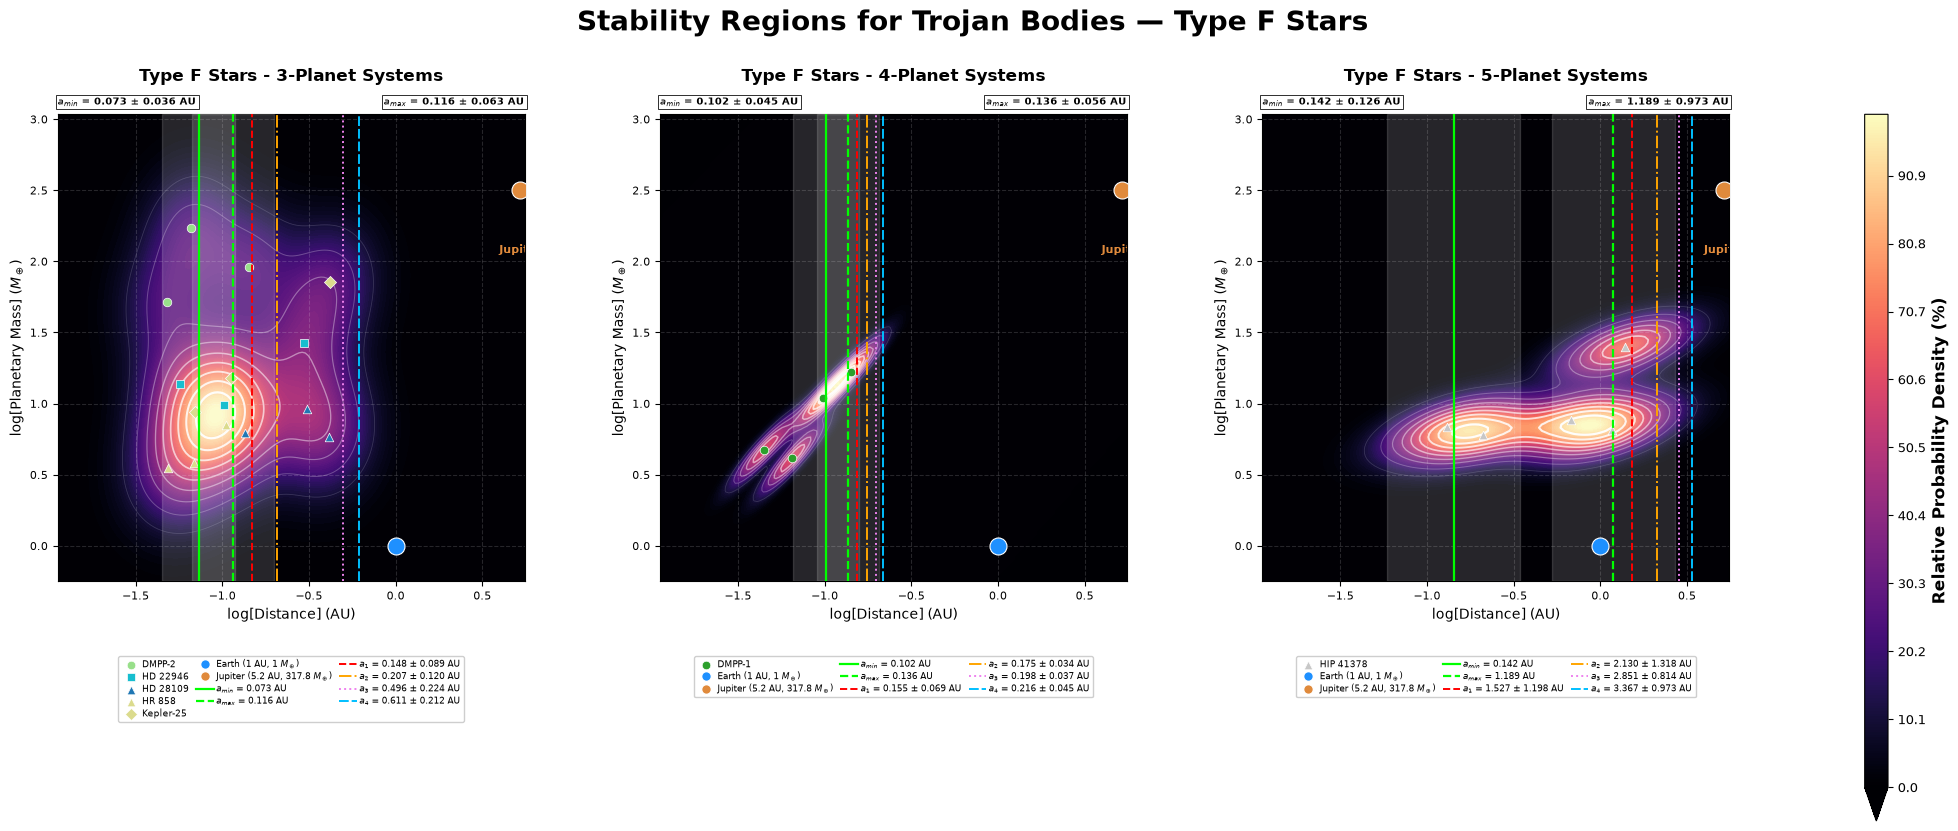

Paneles tipo G: 100%|██████████| 4/4 [05:30<00:00, 82.62s/panel] 


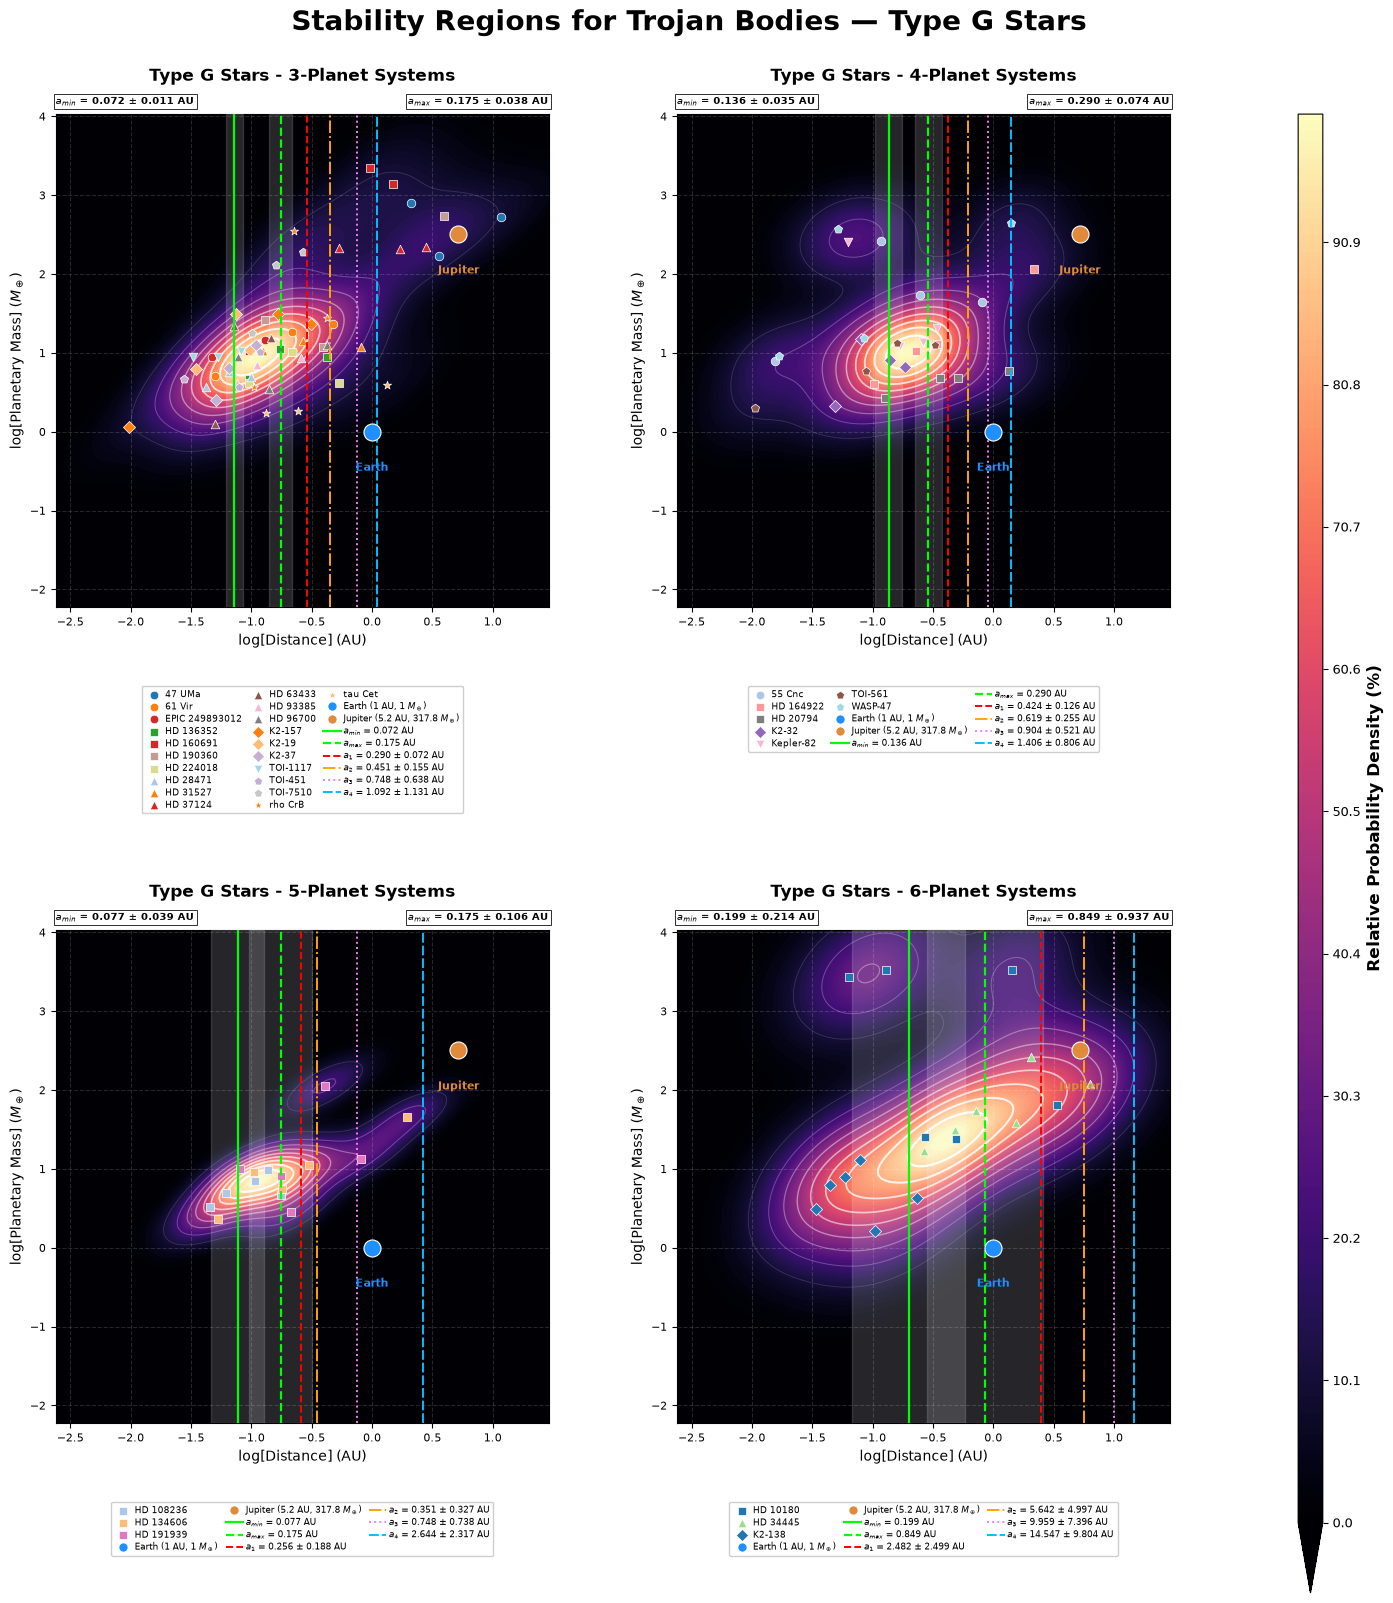

Paneles tipo K: 100%|██████████| 4/4 [05:28<00:00, 82.04s/panel] 


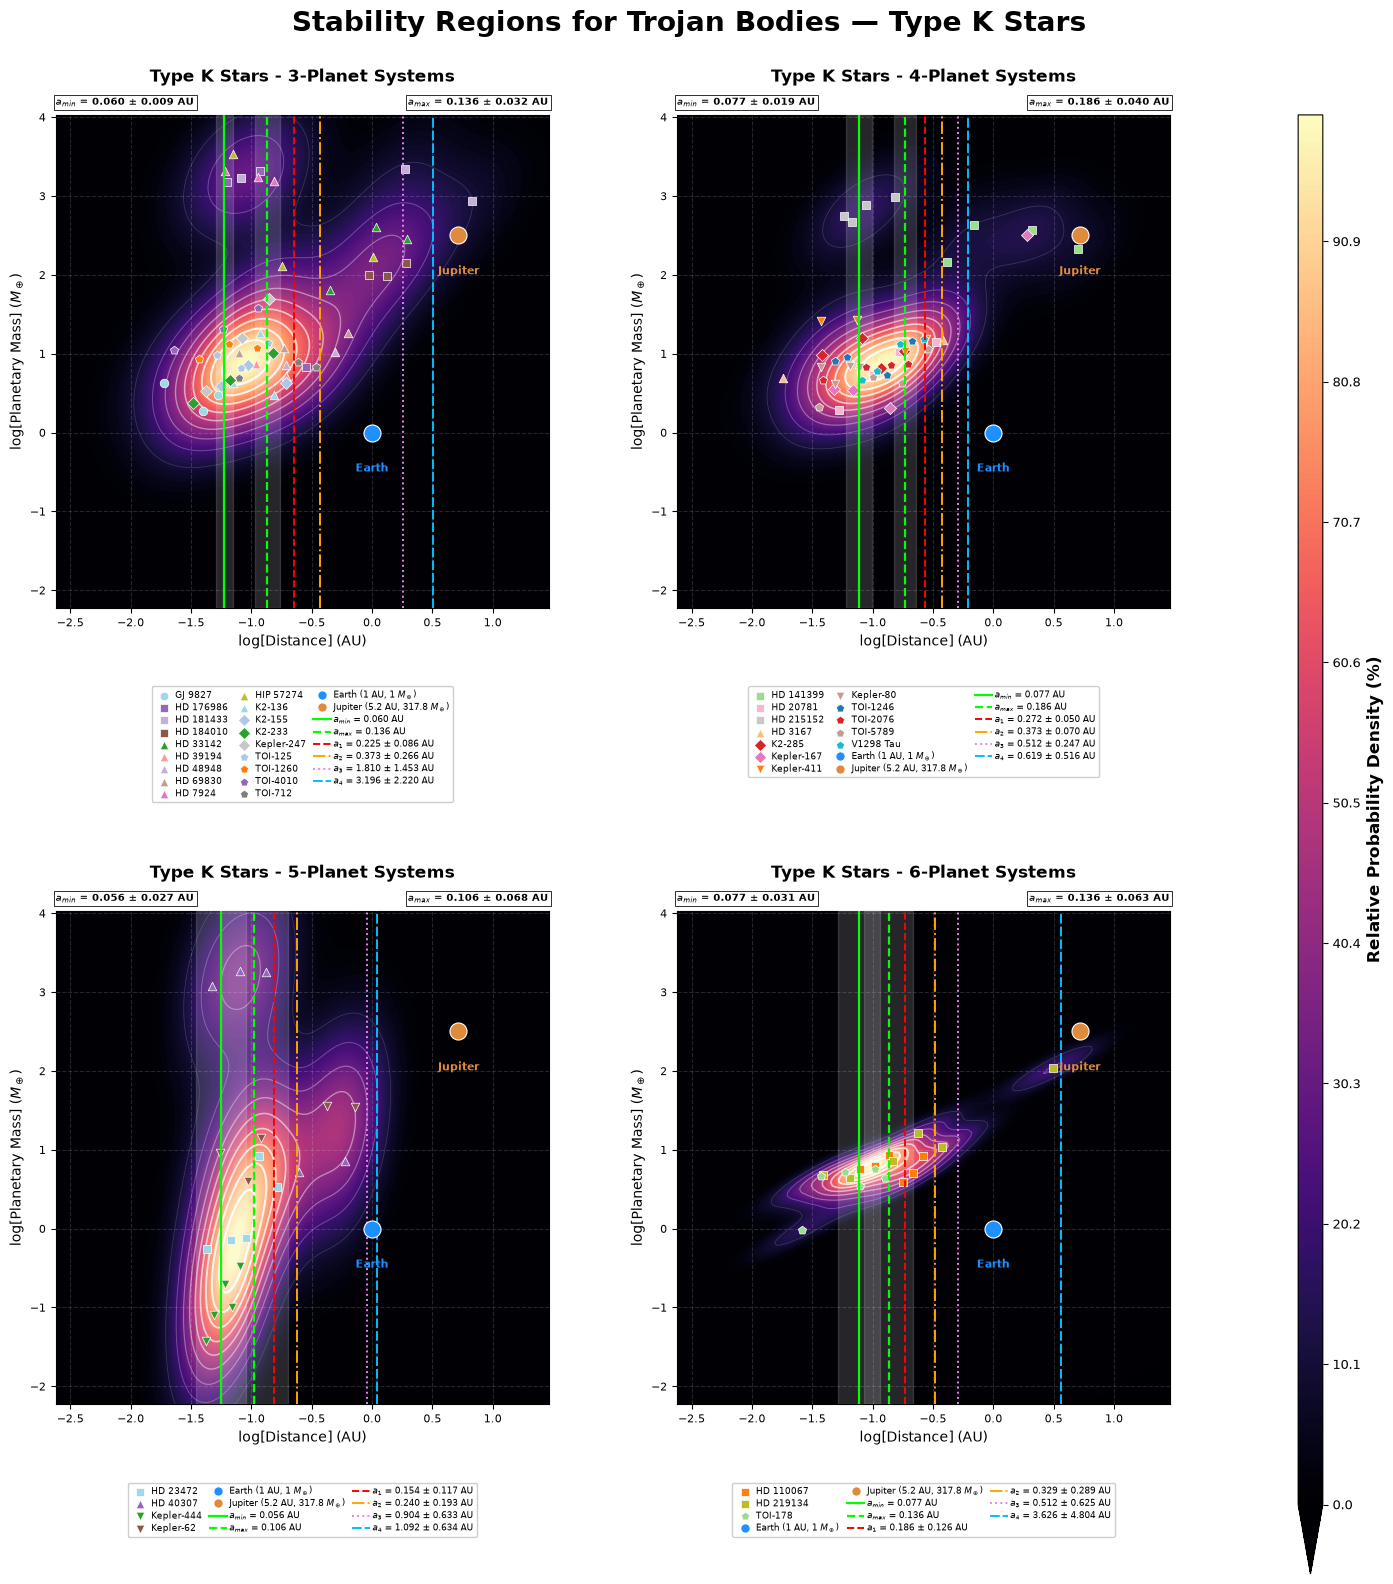

Paneles tipo M: 100%|██████████| 4/4 [06:22<00:00, 95.69s/panel] 


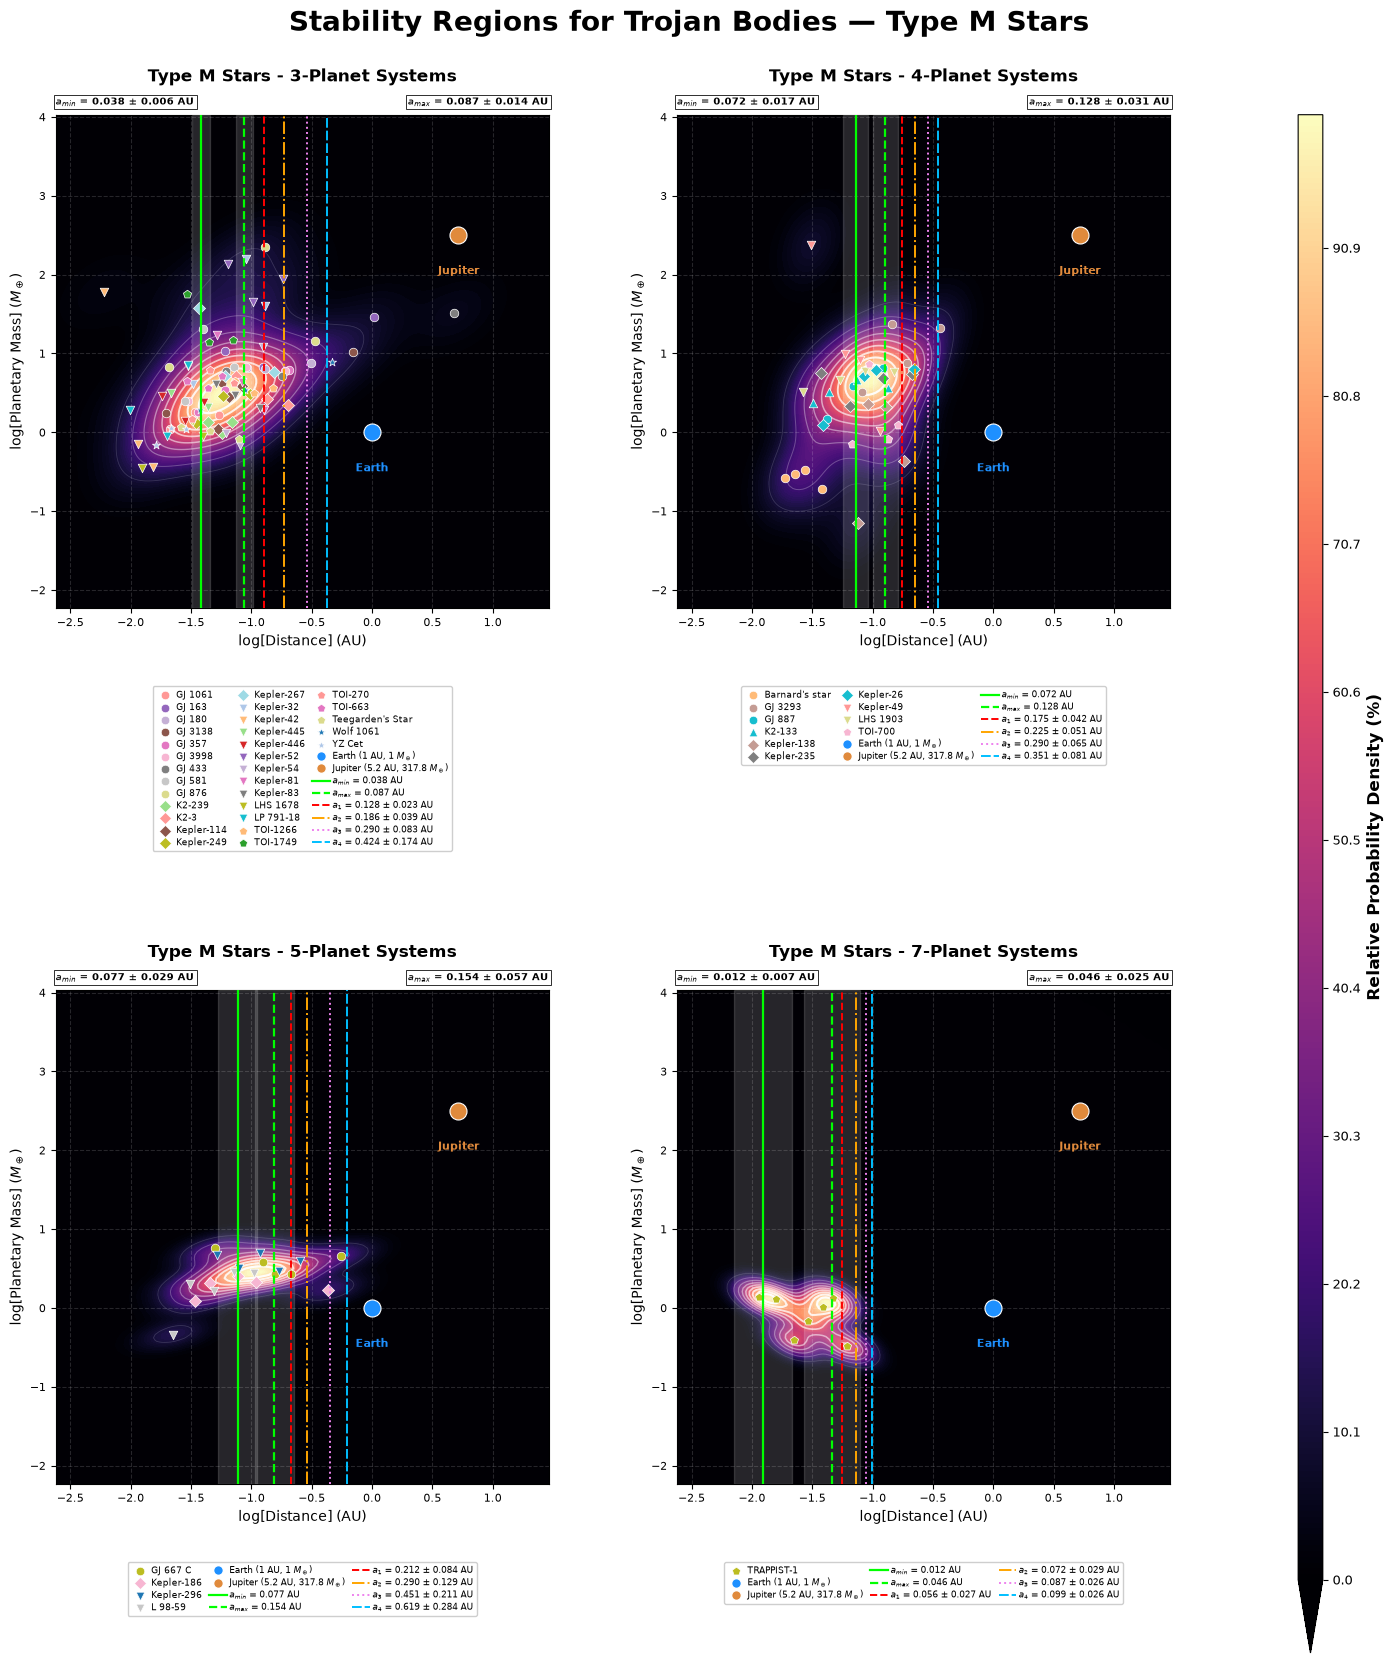

Tipo  Num_Planetas  a_min_UA  sigma_a_min  a_max_UA  sigma_a_max   a_1_UA  sigma_a_1   a_2_UA  sigma_a_2   a_3_UA  sigma_a_3    a_4_UA  sigma_a_4
   F             3  0.073066     0.035598  0.115510     0.063341 0.148290   0.089246 0.206904   0.119963 0.496016   0.223944  0.610811   0.212401
   F             4  0.101946     0.044525  0.136442     0.056472 0.154595   0.069011 0.175162   0.033801 0.198467   0.036702  0.215701   0.044803
   F             5  0.142243     0.126113  1.189109     0.972959 1.526563   1.198474 2.129964   1.317704 2.850675   0.814058  3.367258   0.972742
   G             3  0.072293     0.011472  0.175002     0.037565 0.290029   0.072185 0.451249   0.154962 0.747851   0.638080  1.092356   1.130883
   G             4  0.135939     0.034578  0.290029     0.073996 0.423634   0.126150 0.618786   0.254712 0.903836   0.521242  1.406254   0.806027
   G             5  0.077005     0.038901  0.175002     0.105764 0.255618   0.188401 0.350523   0.327069 0.747851   0.737532

In [2]:
if __name__ == "__main__":
    df_datos, directorio_base = extraer_datos_personalizados()
    if df_datos.empty:
        print("No se extrajeron datos.")
    else:
        
        resumen_limites = plot_figuras_por_tipo(df_datos, directorio_base)
        print(resumen_limites.to_string(index=False))